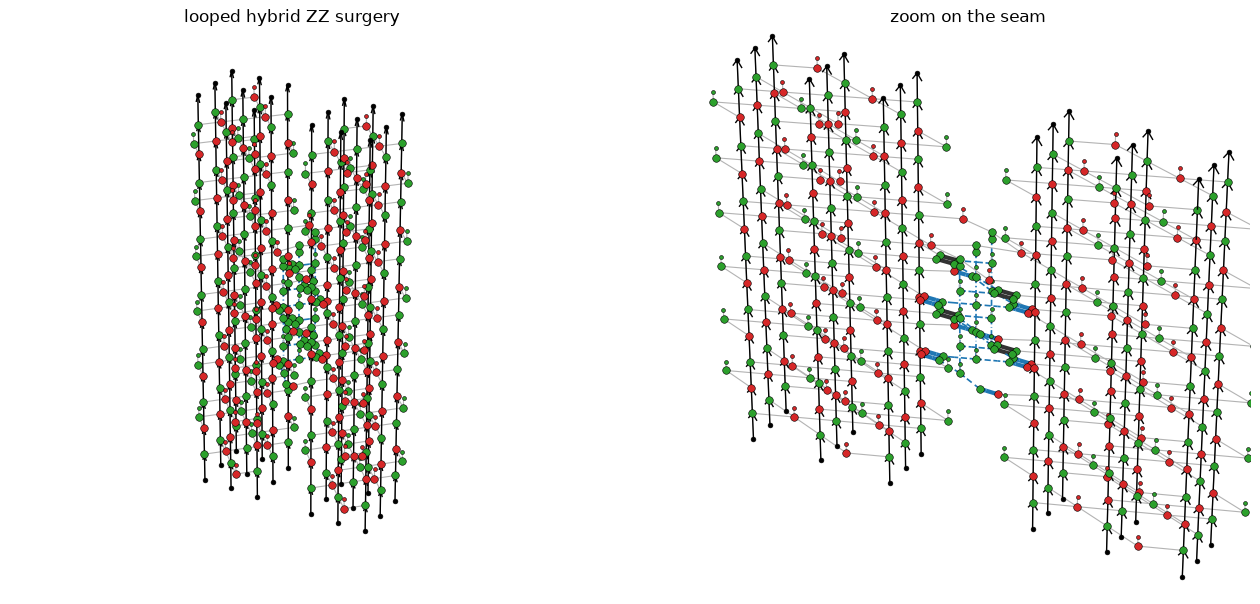

In [1]:
%matplotlib widget

import matplotlib.pyplot as plt

from dizx.realisation import RealisedSED
from dizx.surgery import two_patch_surgery
from dizx.transformations import loop_boundary, prepare_cluster_region

d = 3
s = two_patch_surgery(d, "ZZ", rounds=(2, 2, 2))
r1, r2, _ = s.rounds
seam_data = {v for v in s.sed.types if v[0] == "data" and v[-1] in set(s.seam)}
merge_gens = {g for v in seam_data for g in s.sed.graph.neighbors(v)
            if g[0] == "gen" and r1 <= g[1] < r1 + r2}
hsed, S = prepare_cluster_region(s.sed, seam_data | merge_gens)
lsed, S2, rungs = loop_boundary(hsed, S)
real = RealisedSED.hybrid(lsed, S2, {r: "bell" for r in rungs})

fig = plt.figure(figsize=(16, 9))
real.draw(ax=fig.add_subplot(1, 2, 1, projection="3d"), title="looped hybrid ZZ surgery")
ax = real.draw(ax=fig.add_subplot(1, 2, 2, projection="3d"), title="zoom on the seam")
ax.set_xlim(d - 1.5, d + 1.5)
plt.show()
